In [2]:
"""
TransUNet + MaxSig + with MaxSig-Aware Loss (MSAL) — training + test evaluation
"""

import os
from glob import glob
from time import perf_counter

import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import StepLR

from TransUnet.vit_seg_modeling import VisionTransformer as ViT_seg
from TransUnet.vit_seg_modeling import CONFIGS as CONFIGS_ViT_seg


# ============================================================
# 0) Config
# ============================================================
ROOT = '/home/jupyter-r.yazdi/myproject/dti3d/0pycodes/UnetMaxsig/BLUI/'
config = {
    "lr": 1e-4,
    "batch_size": 8,
    "epochs": 100,
    "img_size": 256,
    "vit_name": "R50-ViT-B_16",
    "pretrained_path": "None"
}


# ============================================================
# 1) Dataset
# ============================================================
class mydataset(Dataset):
    def __init__(self, images_dir, masks_dir, transforms_img=None):
        self.images_dir = images_dir
        self.masks_dir = masks_dir
        self.transforms_img = transforms_img
        self.mask_names = glob(masks_dir + "*.tif")

    def __len__(self):
        return len(self.mask_names)

    def __getitem__(self, index):
        mask_name = self.mask_names[index]
        mask = cv2.imread(mask_name, cv2.IMREAD_ANYDEPTH)
        mask = (mask - mask.min()) / (mask.max() - mask.min())
        mask = (mask > 0).astype(np.float32)
        mask = cv2.resize(mask, (256, 256), interpolation=cv2.INTER_AREA)

        imgn = mask_name.replace('/masks/', '/images/').replace('Mask.tif','Image.bmp')
        image = cv2.imread(imgn, cv2.IMREAD_ANYDEPTH)
        image = (image - image.min()) / (image.max() - image.min()).astype(np.float32)
        image = cv2.resize(image, (256, 256), interpolation=cv2.INTER_AREA)

        if self.transforms_img is not None:
            transformed = self.transforms_img(image=image, mask=mask)
            image = transformed["image"]
            mask = transformed["mask"]

        return image, mask


def build_dataloaders(root, batch_size, img_size=256):
    resize = A.Resize(img_size, img_size)

    train_transform = A.Compose([resize, ToTensorV2()])
    val_transform = A.Compose([resize, ToTensorV2()])
    test_transform = A.Compose([resize, ToTensorV2()])

    train_ds = mydataset(root + 'dataset/train/images/', root + 'dataset/train/masks/', train_transform)
    val_ds = mydataset(root + 'dataset/val/images/', root + 'dataset/val/masks/', val_transform)
    test_ds = mydataset(root + 'dataset/test/images/', root + 'dataset/test/masks/', test_transform)

    print("train:", len(train_ds), " val:", len(val_ds), " test:", len(test_ds))

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)
    return train_loader, val_loader, test_loader

/home/jupyter-r.yazdi/.local/lib/python3.10/site-packages/albumentations/check_version.py:49: UserWarning: Error fetching version info <urlopen error [Errno 101] Network is unreachable>
  data = fetch_version_info()


In [3]:
# ============================================================
# 2) MaxSigLayerNormalized
# ============================================================
class MaxSigLayerNormalized(nn.Module):
    """
    Args:
        ch_in (int): input channels
        ch_out (int): output channels
        kernel_size (int): odd recommended
        stride (int): keep 1 to preserve H,W
        use_sigmoid_input (bool): apply sigmoid(x) before unfolding
    """
    def __init__(
        self,
        ch_in: int,
        ch_out: int,
        kernel_size: int,
        stride: int = 1,
        use_sigmoid_input: bool = True,
    ):
        super().__init__()
        assert kernel_size >= 1
        self.ch_in = ch_in
        self.ch_out = ch_out
        self.kernel_size = kernel_size
        self.stride = stride
        self.use_sigmoid_input = use_sigmoid_input

        self.padding = (kernel_size - 1) // 2
        self.kernel_area = kernel_size ** 2
        self.center_index = self.kernel_area // 2

        # learnable patch weights / bias (shared)
        self.weight = nn.Parameter(torch.rand(1, 1, self.kernel_area, 1, 1))
        self.bias   = nn.Parameter(torch.zeros(1, 1, self.kernel_area, 1, 1))

        # learnable scalars
        self.weight_center = nn.Parameter(torch.tensor(1.0))
        self.weight_median = nn.Parameter(torch.tensor(1.0))

        # proper projection
        self.proj = nn.Conv2d(ch_in, ch_out, kernel_size=1, bias=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, C_in, H, W = x.shape
        assert C_in == self.ch_in, f"Expected {self.ch_in} channels, got {C_in}"

        x_in = torch.sigmoid(x) if self.use_sigmoid_input else x

        x_unfold = F.unfold(
            x_in,
            kernel_size=self.kernel_size,
            padding=self.padding,
            stride=self.stride,
        )  # (B, C_in*K*K, L)

        _, CK2, L = x_unfold.shape
        assert CK2 == C_in * self.kernel_area

        out_h = (H + 2 * self.padding - self.kernel_size) // self.stride + 1
        out_w = (W + 2 * self.padding - self.kernel_size) // self.stride + 1

        x_unfold = x_unfold.view(B, C_in, self.kernel_area, out_h, out_w)

        w = torch.sigmoid(self.weight)  # (1,1,K*K,1,1)
        b = torch.sigmoid(self.bias)    # (1,1,K*K,1,1)

        D = torch.maximum(w, x_unfold) + b  # (B,C,K*K,out_h,out_w)

        mean_stat = torch.mean(D, dim=2)         # (B,C,out_h,out_w)
        median_stat, _ = torch.median(D, dim=2)  # (B,C,out_h,out_w)

        center_values = x_unfold[:, :, self.center_index, :, :]  # (B,C,out_h,out_w)

        out = (
            self.weight_center * center_values
            + self.weight_median * median_stat
            - mean_stat
        )  # (B,C_in,out_h,out_w)

        out = self.proj(out)  # (B,C_out,out_h,out_w)
        return out


class GatedMaxSigWrapper(nn.Module):
    """gamma starts at 0 -> wrapped stage == original stage at init."""
    def __init__(self, inner_module, ch, kernel_sig=3, gamma_init=0.0, use_sigmoid_input=True):
        super().__init__()
        self.inner = inner_module
        self.maxsig = MaxSigLayerNormalized(ch, ch, kernel_sig, use_sigmoid_input=use_sigmoid_input)
        self.post = nn.Sequential(nn.BatchNorm2d(ch), nn.LeakyReLU(0.1, inplace=True))
        self.gamma = nn.Parameter(torch.tensor(gamma_init))

    def forward(self, x):
        x = self.inner(x)
        m = self.post(self.maxsig(x))
        return x + self.gamma * m


def inject_maxsig_into_resnet(vit_seg_model, stages=("block1", "block2"),
                              kernel_sig=3, gamma_init=0.0):
    resnet = vit_seg_model.transformer.embeddings.hybrid_model
    for stage_name in stages:
        stage_module = getattr(resnet.body, stage_name)
        last_unit = list(stage_module.children())[-1]
        out_ch = last_unit.gn3.num_channels if hasattr(last_unit, "gn3") \
            else last_unit.conv3.out_channels
        wrapped = GatedMaxSigWrapper(stage_module, ch=out_ch,
                                     kernel_sig=kernel_sig, gamma_init=gamma_init)
        setattr(resnet.body, stage_name, wrapped)
    return vit_seg_model


# ============================================================
# 3) MaxSig-Aware Loss (MSAL)
# ============================================================
class MaxSigFeatureHook:
    """Collects MaxSigLayerNormalized outputs during forward pass."""
    def __init__(self, model):
        self.features = {}
        self.handles = []
        for name, module in model.named_modules():
            if isinstance(module, MaxSigLayerNormalized):
                self.handles.append(
                    module.register_forward_hook(self._make_hook(name))
                )

    def _make_hook(self, name):
        def hook(_, __, output):
            self.features[name] = output
        return hook

    def clear(self):
        self.features.clear()

    def remove(self):
        for h in self.handles:
            h.remove()


def _local_stats(x, k=3):
    """Return (center, mean, median) over kxk patches. x: (B,C,H,W)."""
    B, C, H, W = x.shape
    pad = k // 2
    uf = F.unfold(x, kernel_size=k, padding=pad)              # (B, C*k*k, L)
    uf = uf.view(B, C, k * k, H, W)
    center = uf[:, :, k * k // 2, :, :]
    mean_l = uf.mean(dim=2)
    med_l, _ = uf.median(dim=2)
    return center, mean_l, med_l


class MaxSigAwareLoss(nn.Module):
    """
    L = a_bce * BCE + a_dice * Dice
        + a_sas * SAS
        + a_mbe * MBE
        + a_mmd * MMD
        + a_pdr * PDR(model)
    """
    def __init__(self,
                 alpha_bce=1.0,
                 alpha_dice=1.0,
                 alpha_sas=0.5,
                 alpha_mbe=0.3,
                 alpha_mmd=0.2,
                 alpha_pdr=1e-3,
                 k=3, eps=1e-7):
        super().__init__()
        self.a_bce   = alpha_bce
        self.a_dice  = alpha_dice
        self.a_sas   = alpha_sas
        self.a_mbe   = alpha_mbe
        self.a_mmd   = alpha_mmd
        self.a_pdr   = alpha_pdr
        self.k = k
        self.eps = eps
        self.bce = nn.BCEWithLogitsLoss(reduction='none')

    # ---- term 1: Significance-Aligned Segmentation ----
    def sas_loss(self, probs, targets):
        pc, pm, pmd = _local_stats(probs, self.k)
        tc, tm, tmd = _local_stats(targets, self.k)
        sig_p = (pc - pm).abs() + (pc - pmd).abs()
        sig_t = (tc - tm).abs() + (tc - tmd).abs()
        sig_p = sig_p / (sig_p.amax(dim=(2, 3), keepdim=True) + self.eps)
        sig_t = sig_t / (sig_t.amax(dim=(2, 3), keepdim=True) + self.eps)
        return F.l1_loss(sig_p, sig_t)

    # ---- term 2: Max-Bounded Boundary Emphasis ----
    def mbe_loss(self, logits, targets):
        bce = self.bce(logits, targets)                       # (B,1,H,W)
        pc, pm, _ = _local_stats(torch.sigmoid(logits), self.k)
        tc, tm, _ = _local_stats(targets, self.k)
        bnd_p = (pc - pm).abs()
        bnd_t = (tc - tm).abs()
        w = torch.maximum(bnd_p, bnd_t)
        w = w / (w.mean() + self.eps)
        return (bce * w).mean()

    # ---- term 3: Median-Mean Divergence ----
    def mmd_loss(self, probs, targets):
        _, pm, pmd = _local_stats(probs, self.k)
        _, tm, tmd = _local_stats(targets, self.k)
        div_p = (pm - pmd).abs()
        div_t = (tm - tmd).abs()
        return F.l1_loss(div_p, div_t)

    # ---- term 4: Parameter Diversity Regularization ----
    def pdr_loss(self, model):
        reg = logits = None
        for m in model.modules():
            if isinstance(m, MaxSigLayerNormalized):
                w = torch.sigmoid(m.weight).clamp(self.eps, 1 - self.eps)  # (1,1,K*K,1,1)
                p = w / (w.sum() + self.eps)
                ent = -(p * p.log()).sum()
                pos_pen = F.relu(-m.weight_center) + F.relu(-m.weight_median)
                bal = (m.weight_center - m.weight_median).abs()
                term = -ent + pos_pen + 0.1 * bal
                reg = term if reg is None else reg + term
        return reg if reg is not None else torch.tensor(0.0, device=next(model.parameters()).device)

    def dice_loss(self, probs, targets):
        inter = (probs * targets).sum(dim=(2, 3))
        union = (probs + targets).sum(dim=(2, 3))
        dice = (2 * inter + self.eps) / (union + self.eps)
        return 1 - dice.mean()

    def forward(self, logits, targets, model=None):
        probs = torch.sigmoid(logits)
        loss  = self.a_bce  * self.bce(logits, targets).mean()
        loss  = loss + self.a_dice * self.dice_loss(probs, targets)
        loss  = loss + self.a_sas  * self.sas_loss(probs, targets)
        loss  = loss + self.a_mbe  * self.mbe_loss(logits, targets)
        loss  = loss + self.a_mmd  * self.mmd_loss(probs, targets)
        if model is not None and self.a_pdr > 0:
            loss = loss + self.a_pdr * self.pdr_loss(model)
        return loss


# ============================================================
# 4) Build model — TransUNet + MaxSig only
# ============================================================
def build_model(vit_name, img_size, num_classes, pretrained_path,
                maxsig_stages=("block1", "block2"), maxsig_kernel=3):
    config_vit = CONFIGS_ViT_seg[vit_name]
    config_vit.n_classes = num_classes
    config_vit.n_skip = 3
    if "R50" in vit_name:
        config_vit.patches.grid = (img_size // 16, img_size // 16)

    model = ViT_seg(config_vit, img_size=img_size, num_classes=num_classes)
    if pretrained_path and os.path.exists(pretrained_path):
        model.load_from(weights=np.load(pretrained_path))
    else:
        print("WARNING: pretrained_path not found — training from random init.")

    model = inject_maxsig_into_resnet(
        model, stages=maxsig_stages, kernel_sig=maxsig_kernel, gamma_init=0.0
    )
    return model


# ============================================================
# 5) Metrics
# ============================================================
@torch.no_grad()
def dice_score(logits, targets, eps=1e-7):
    preds = (torch.sigmoid(logits) > 0.5).float()
    inter = (preds * targets).sum()
    union = (preds + targets).sum()
    return float((2 * inter + eps) / (union + eps))


def prep_batch(inputs, mask, device):
    x = inputs.to(device).float()
    if x.dim() == 3:
        x = x.unsqueeze(1)
    if x.shape[1] == 1:
        x = x.repeat(1, 3, 1, 1)
    y = mask.to(device).unsqueeze(1).float()
    return x, y


# ============================================================
# 6) Train loop — with exact report format
# ============================================================
def train_one(model, train_loader, val_loader, device, epochs, lr,
              loss_fn, tag="model", ckpt_path=None):
    model.to(device)
    optimizer = optim.AdamW(model.parameters(), lr=lr)
    scheduler = StepLR(optimizer, step_size=100, gamma=0.5)
    scaler = torch.amp.GradScaler('cuda') if device == "cuda" else None

    history = {"train_loss": [], "val_loss": [], "val_dice": []}
    best_dice = 0.0
    best_epoch = 0

    for epoch in range(epochs):
        t0 = perf_counter()
        current_lr = optimizer.param_groups[0]['lr']

        print(f"epoch  {epoch + 1}  started!  LR= [{current_lr}]")

        # ---- Training ----
        model.train()
        running = 0.0
        for inputs, mask in train_loader:
            x, y = prep_batch(inputs, mask, device)
            optimizer.zero_grad()
            if scaler is not None:
                with torch.autocast(device_type="cuda"):
                    logits = model(x)
                    loss = loss_fn(logits, y, model=model)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            else:
                logits = model(x)
                loss = loss_fn(logits, y, model=model)
                loss.backward()
                optimizer.step()
            running += loss.item()
        scheduler.step()
        train_loss = running / len(train_loader)

        # ---- Validation ----
        model.eval()
        val_running, dice_running = 0.0, 0.0
        with torch.no_grad():
            for inputs, mask in val_loader:
                x, y = prep_batch(inputs, mask, device)
                logits = model(x)
                val_running += loss_fn(logits, y, model=model).item()
                dice_running += dice_score(logits, y)

        val_loss = val_running / len(val_loader)
        val_dice = dice_running / len(val_loader)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_dice"].append(val_dice)

        # ---- Report (exact format) ----
        print(f"train_loss:  {train_loss}")
        print(f"val_loss:  {val_loss}")
        print(f"Validation_Dice Score = {val_dice:.12f}")

        if val_dice > best_dice:
            best_dice = val_dice
            best_epoch = epoch + 1
            if ckpt_path:
                torch.save(model.state_dict(), ckpt_path)
            print("The best model saved...")

        print(f"Best validation dice= {best_dice}  in epoch  {best_epoch}")
        elapsed = perf_counter() - t0
        print(f"Epoch finished in {elapsed} seconds.")
        print()

    return history, best_dice, best_epoch


# ============================================================
# 7) Test evaluation
# ============================================================
def evaluate_test(model, test_loader, device, loss_fn, ckpt_path):
    if os.path.exists(ckpt_path):
        model.load_state_dict(torch.load(ckpt_path))
    model.to(device)
    model.eval()

    test_loss = 0.0
    test_dice = 0.0
    with torch.no_grad():
        for inputs, mask in test_loader:
            x, y = prep_batch(inputs, mask, device)
            logits = model(x)
            test_loss += loss_fn(logits, y, model=model).item()
            test_dice += dice_score(logits, y)

    test_loss /= len(test_loader)
    test_dice /= len(test_loader)

    print("=" * 80)
    print("Test Dataset Evaluation")
    print("=" * 80)
    print(f"test_loss:  {test_loss}")
    print(f"Test_Dice Score = {test_dice:.12f}")
    print("=" * 80)

    return test_loss, test_dice


# ============================================================
# 8) Plot history
# ============================================================
def plot_history(history, title, save_path):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["train_loss"], label="train_loss")
    axes[0].plot(history["val_loss"], label="val_loss")
    axes[0].set_title(f"{title} - Loss")
    axes[0].legend()

    axes[1].plot(history["val_dice"], label="val_dice")
    axes[1].set_title(f"{title} - Validation Dice")
    axes[1].legend()
    plt.tight_layout()
    plt.savefig(save_path)
    plt.show()

/home/jupyter-r.yazdi/.local/lib/python3.10/site-packages/albumentations/check_version.py:49: UserWarning: Error fetching version info <urlopen error [Errno 101] Network is unreachable>
  data = fetch_version_info()


train: 162  val: 35  test: 35
Training TransUNet + MaxSig + MSAL
epoch  1  started!  LR= [0.0001]
train_loss:  1.5370950925917852
val_loss:  1.5931987285614013
Validation_Dice Score = 0.438235664368
The best model saved...
Best validation dice= 0.4382356643676758  in epoch  1
Epoch finished in 14.728290303843096 seconds.

epoch  2  started!  LR= [0.0001]
train_loss:  1.277633513723101
val_loss:  2.083493876457214
Validation_Dice Score = 0.384860044718
Best validation dice= 0.4382356643676758  in epoch  1
Epoch finished in 13.087817494058982 seconds.

epoch  3  started!  LR= [0.0001]
train_loss:  1.1876132147652763
val_loss:  1.1712682723999024
Validation_Dice Score = 0.700122094154
The best model saved...
Best validation dice= 0.7001220941543579  in epoch  3
Epoch finished in 14.919652696000412 seconds.

epoch  4  started!  LR= [0.0001]
train_loss:  1.104866047700246
val_loss:  1.1155602216720581
Validation_Dice Score = 0.765531492233
The best model saved...
Best validation dice= 0.765

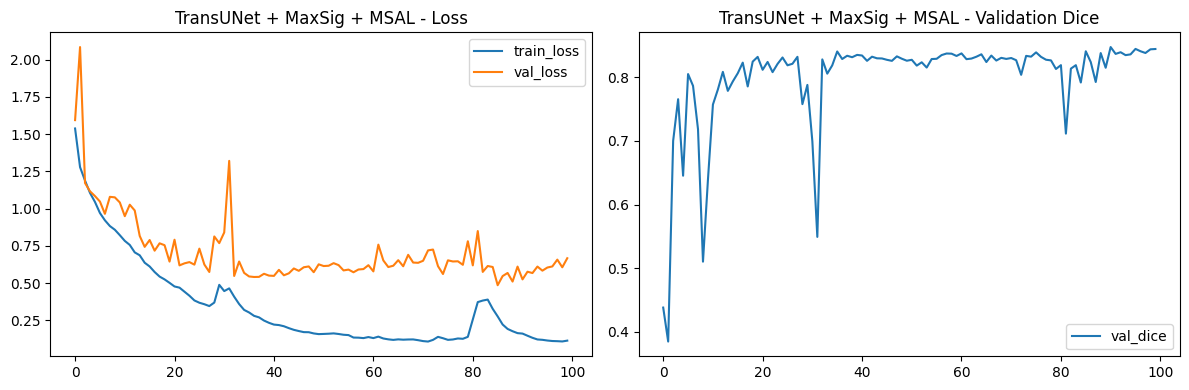

In [ ]:
# ============================================================
# 9) Main
# ============================================================
if __name__ == "__main__":
    torch.manual_seed(42)
    device = "cuda" if torch.cuda.is_available() else "cpu"

    train_loader, val_loader, test_loader = build_dataloaders(
        ROOT, config["batch_size"], config["img_size"]
    )

    model = build_model(
        vit_name=config["vit_name"],
        img_size=config["img_size"],
        num_classes=1,
        pretrained_path=config["pretrained_path"],
        maxsig_stages=("block1", "block2"),
        maxsig_kernel=3,
    )

    criterion = MaxSigAwareLoss(
        alpha_bce=1.0, alpha_dice=1.0,
        alpha_sas=0.5, alpha_mbe=0.3, alpha_mmd=0.2, alpha_pdr=1e-3,
    ).to(device)

    ckpt_path = ROOT + "best-transunet-maxsig-msal.pt"

    print("=" * 80)
    print("Training TransUNet + MaxSig + MSAL")
    print("=" * 80)

    history, best_dice, best_epoch = train_one(
        model, train_loader, val_loader, device,
        epochs=config["epochs"], lr=config["lr"],
        loss_fn=criterion,
        tag="TransUNet_MaxSig", ckpt_path=ckpt_path,
    )
    
    print(f"Training completed! Best validation dice = {best_dice} in epoch {best_epoch}")

    # ---- Test evaluation ----
    test_loss, test_dice = evaluate_test(
        model, test_loader, device, criterion, ckpt_path
    )

    plot_history(history, "TransUNet + MaxSig + MSAL", ROOT + "training_history_maxsig_msal.png")

In [ ]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total_params:,}")

 test: 35


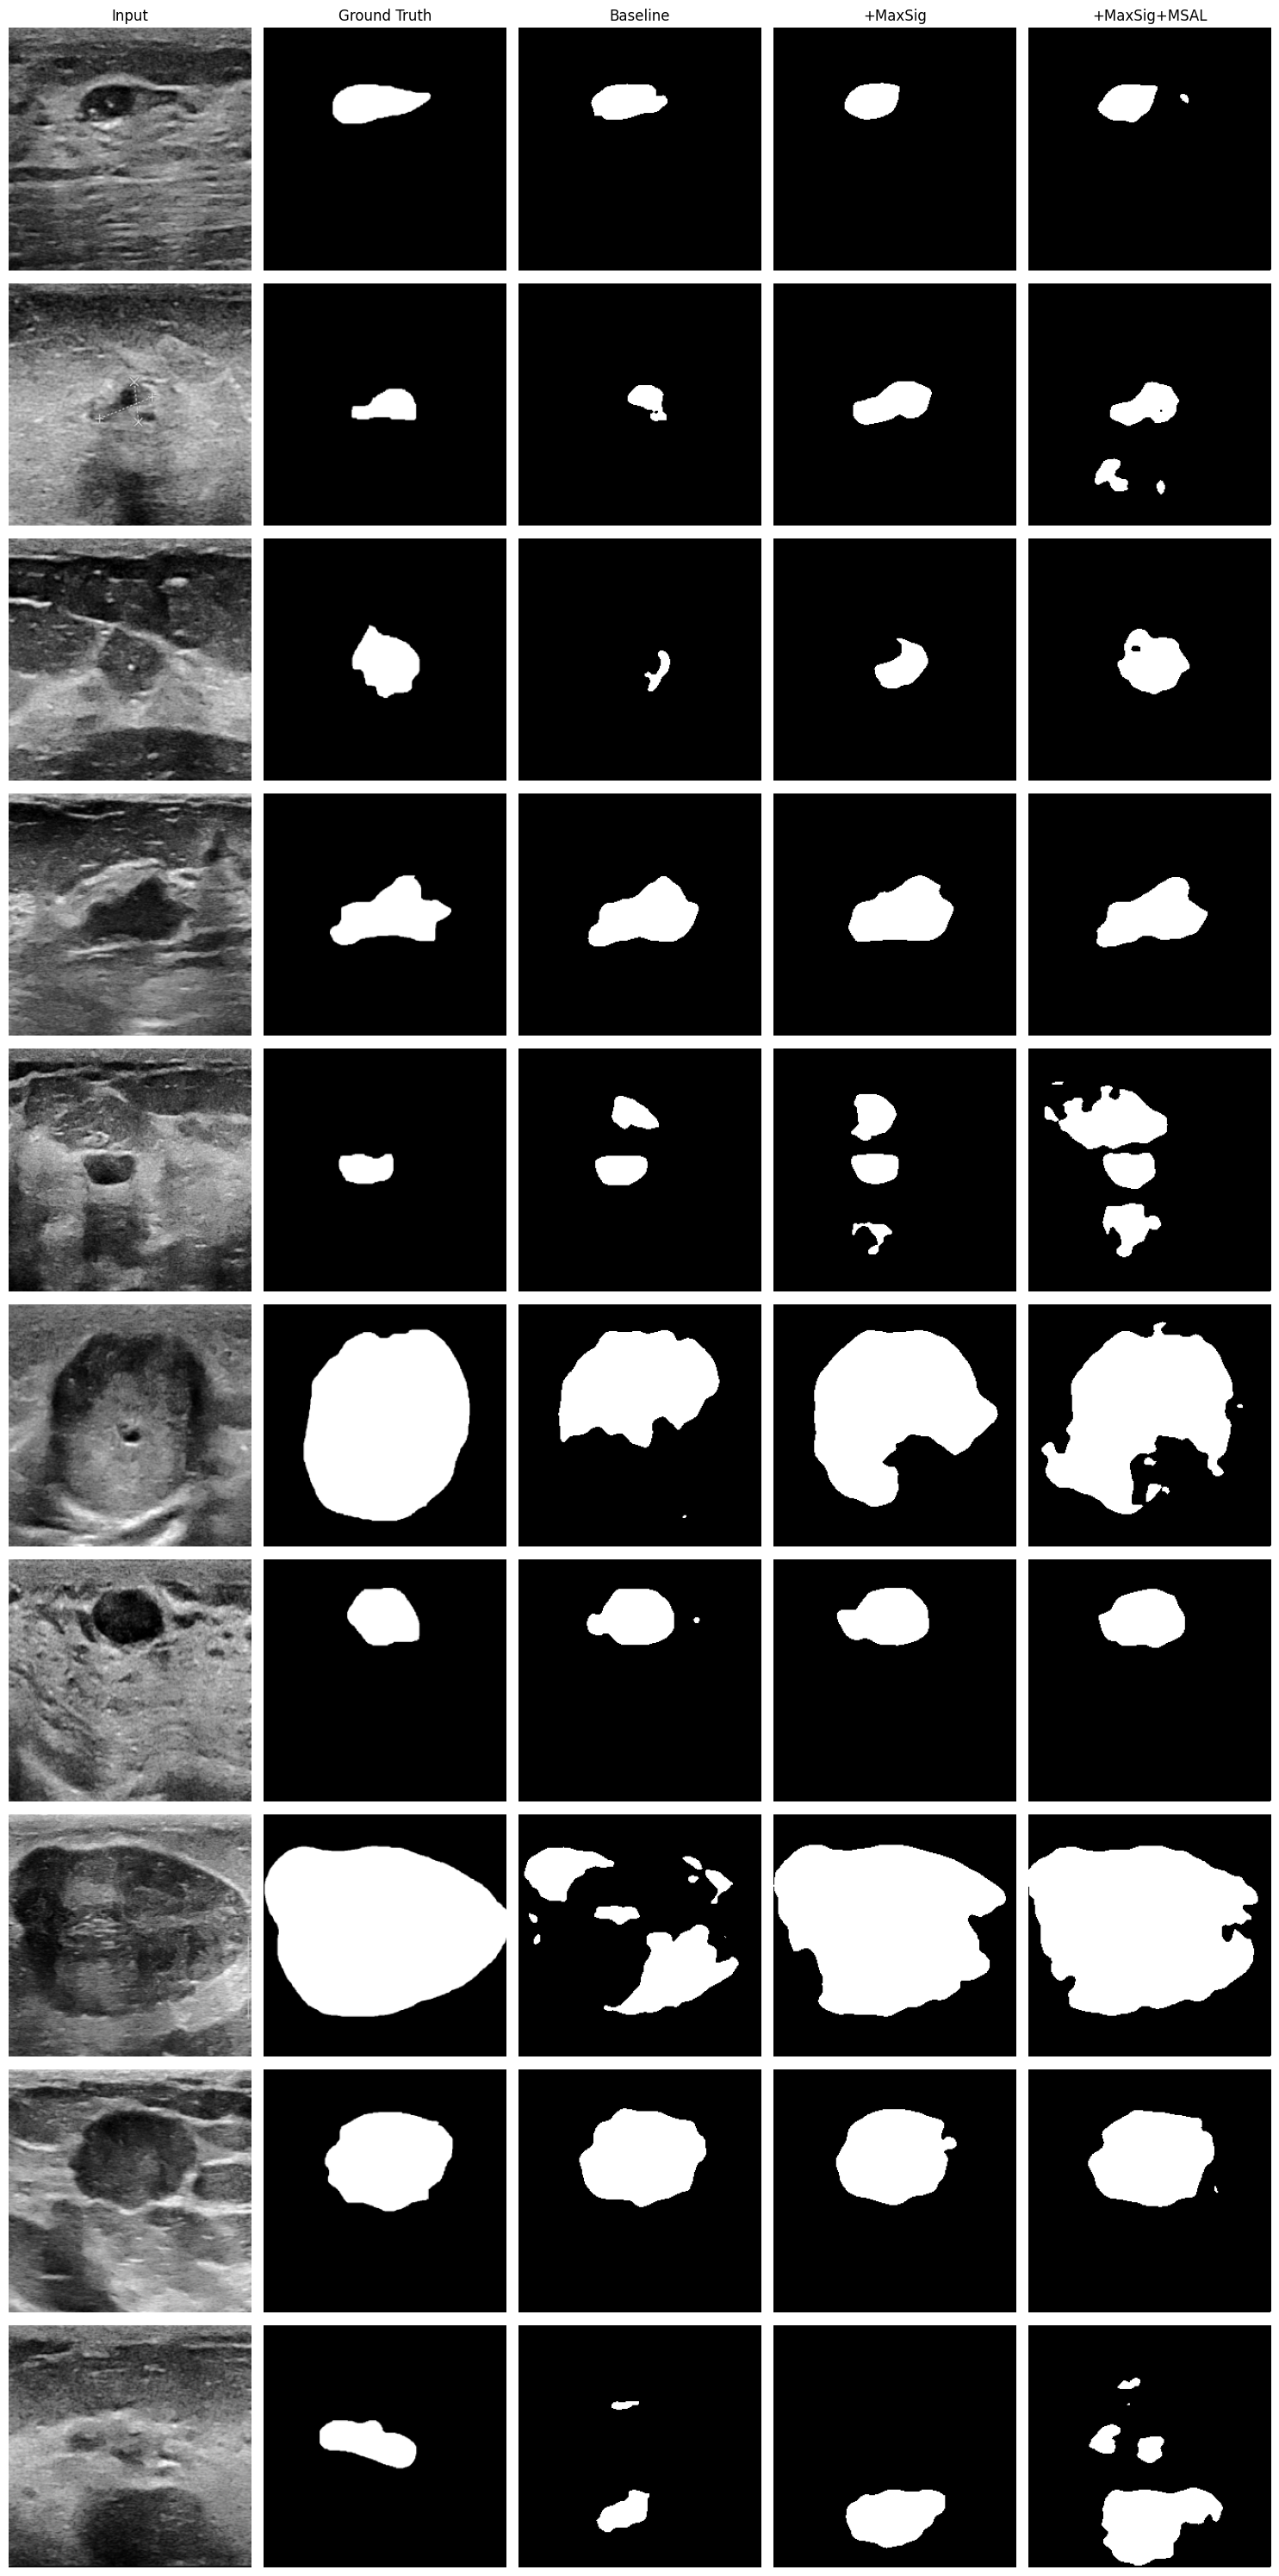

In [9]:
# ============================================================
# Compare Baseline vs +MaxSig vs +MaxSig+MSAL on random test images
# ============================================================

ROOT = '/home/jupyter-r.yazdi/myproject/dti3d/0pycodes/UnetMaxsig/BLUI/'
config = {
    "lr": 1e-4,
    "batch_size": 8,
    "epochs": 100,
    "img_size": 256,
    "vit_name": "R50-ViT-B_16",
    "pretrained_path": "None"
}

import random
import numpy as np
import torch
import matplotlib.pyplot as plt
from TransUnet.vit_seg_modeling import VisionTransformer as ViT_seg
from TransUnet.vit_seg_modeling import CONFIGS as CONFIGS_ViT_seg

device = "cuda" if torch.cuda.is_available() else "cpu"


def build_dataloaders(root, batch_size, img_size=256):
    resize = A.Resize(img_size, img_size)

    test_transform = A.Compose([resize, ToTensorV2()])
    test_ds = mydataset(root + 'dataset/test/images/', root + 'dataset/test/masks/', test_transform)

    print(" test:", len(test_ds))

    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=True)
    return  test_ds,test_loader

# ---- Checkpoint paths (as saved by the three training notebooks) ----
ckpt_baseline    = ROOT + "best-transunet.pt"
ckpt_maxsig      = ROOT + "best-transunet-maxsig.pt"
ckpt_maxsig_msal = ROOT + "best-transunet-maxsig-msal.pt"

# ---- Build the three architectures ----
# Baseline: plain TransUNet (no MaxSig injection)
model_baseline = ViT_seg(
    (lambda cfg: (cfg.__setattr__('n_classes', 1), cfg.__setattr__('n_skip', 3),
                  cfg.__setattr__('patches', cfg.patches), cfg)[-1])(
        CONFIGS_ViT_seg[config["vit_name"]]
    ),
    img_size=config["img_size"], num_classes=1
)
# simpler/cleaner: just reuse build_model with maxsig_stages=() so nothing gets wrapped
def build_baseline_model():
    config_vit = CONFIGS_ViT_seg[config["vit_name"]]
    config_vit.n_classes = 1
    config_vit.n_skip = 3
    if "R50" in config["vit_name"]:
        config_vit.patches.grid = (config["img_size"] // 16, config["img_size"] // 16)
    return ViT_seg(config_vit, img_size=config["img_size"], num_classes=1)

model_baseline    = build_baseline_model()
model_maxsig      = build_model(config["vit_name"], config["img_size"], 1,
                                 pretrained_path="None",
                                 maxsig_stages=("block1", "block2"), maxsig_kernel=3)
model_maxsig_msal = build_model(config["vit_name"], config["img_size"], 1,
                                 pretrained_path="None",
                                 maxsig_stages=("block1", "block2"), maxsig_kernel=3)

# ---- Load best weights ----
model_baseline.load_state_dict(torch.load(ckpt_baseline, map_location=device))
model_maxsig.load_state_dict(torch.load(ckpt_maxsig, map_location=device))
model_maxsig_msal.load_state_dict(torch.load(ckpt_maxsig_msal, map_location=device))

for m in (model_baseline, model_maxsig, model_maxsig_msal):
    m.to(device).eval()

test_ds,test_loader=build_dataloaders(ROOT, batch_size=1, img_size=256)

# ---- Pick 5 random test samples ----
n_show = 10
indices = random.sample(range(len(test_ds)), n_show)

col_titles = ["Input", "Ground Truth", "Baseline", "+MaxSig", "+MaxSig+MSAL"]
fig, axes = plt.subplots(n_show, 5, figsize=(15, 3 * n_show))

with torch.no_grad():
    for row, idx in enumerate(indices):
        image, mask = test_ds[idx]
        x, y = prep_batch(image.unsqueeze(0), mask.unsqueeze(0), device)

        pred_base  = (torch.sigmoid(model_baseline(x))    > 0.5).float().cpu().numpy()[0, 0]
        pred_ms    = (torch.sigmoid(model_maxsig(x))      > 0.5).float().cpu().numpy()[0, 0]
        pred_msal  = (torch.sigmoid(model_maxsig_msal(x)) > 0.5).float().cpu().numpy()[0, 0]

        img_np  = x.cpu().numpy()[0, 0]     # first of the 3 repeated channels
        mask_np = y.cpu().numpy()[0, 0]

        panels = [img_np, mask_np, pred_base, pred_ms, pred_msal]
        cmaps  = ["gray", "gray", "gray", "gray", "gray"]

        for col, (panel, cmap) in enumerate(zip(panels, cmaps)):
            ax = axes[row, col]
            ax.imshow(panel, cmap=cmap)
            ax.axis("off")
            if row == 0:
                ax.set_title(col_titles[col], fontsize=12)
        axes[row, 0].set_ylabel(f"idx {idx}", fontsize=9)

plt.tight_layout()
plt.savefig(ROOT + "comparison_grid_transunet.png", dpi=300, bbox_inches="tight")
plt.show()